# Basics > Probability Calculator: worked examples

<div class="alert alert-info">Four practice problems for the Probability Calculator, solved in Radiant (for Python) and with pyrsm</div>

These are the four examples from the Radiant-for-R probability calculator videos, recreated for Radiant (for Python) and pyrsm. For each one the notebook gives the question, how to set it up in **Basics > Probability calculator** in Radiant (with a screenshot of the inputs and the output), the same calculation in pyrsm, and the answer.

In Radiant, choosing a distribution fills in default parameters and bounds; replace them with the values from the question and clear any bound you do not need. `Values` as the `Calculation type` means you enter x-values and get probabilities; `Probabilities` means you enter probabilities and get the matching x-values (cutoffs).

In [1]:
import pyrsm as rsm

## Example 1: cups of ice cream

The probability distribution of the number of cups of ice cream a customer buys could be described as follows:

* 40% of customers buy 1 cup;
* 30% of customers buy 2 cups;
* 20% of customers buy 3 cups;
* 10% of customers buy 4 cups.

(a) What are the mean and variance of the number of cups of ice cream a customer would buy?<br>
(b) What is the probability of a customer buying 2 or more cups?

**Radiant.** The distribution is discrete, so select `Discrete` as the `Distribution`. Enter `1 2 3 4` as the `Values` and `0.4 0.3 0.2 0.1` as the `Probabilities`, choose `Values` as the `Calculation type`, set the `Lower bound` to 2 and leave the upper bound blank. Press `Calculate`.

![Example 1 in Radiant: discrete distribution with values 1 2 3 4 and probabilities 0.4 0.3 0.2 0.1, lower bound 2](figures/prob-calc-examples/ex1-icecream.png)

**pyrsm.** The same calculation:

Probability Calculator
Distribution : Discrete
Values       : 1 2 3 4
Probabilities: 0.4 0.3 0.2 0.1
Mean         : 2
St. dev      : 1
Lower bound  : 2
Upper bound  : 

P(X  = 2) = 0.3
P(X  < 2) = 0.4
P(X <= 2) = 0.7
P(X  > 2) = 0.3
P(X >= 2) = 0.6


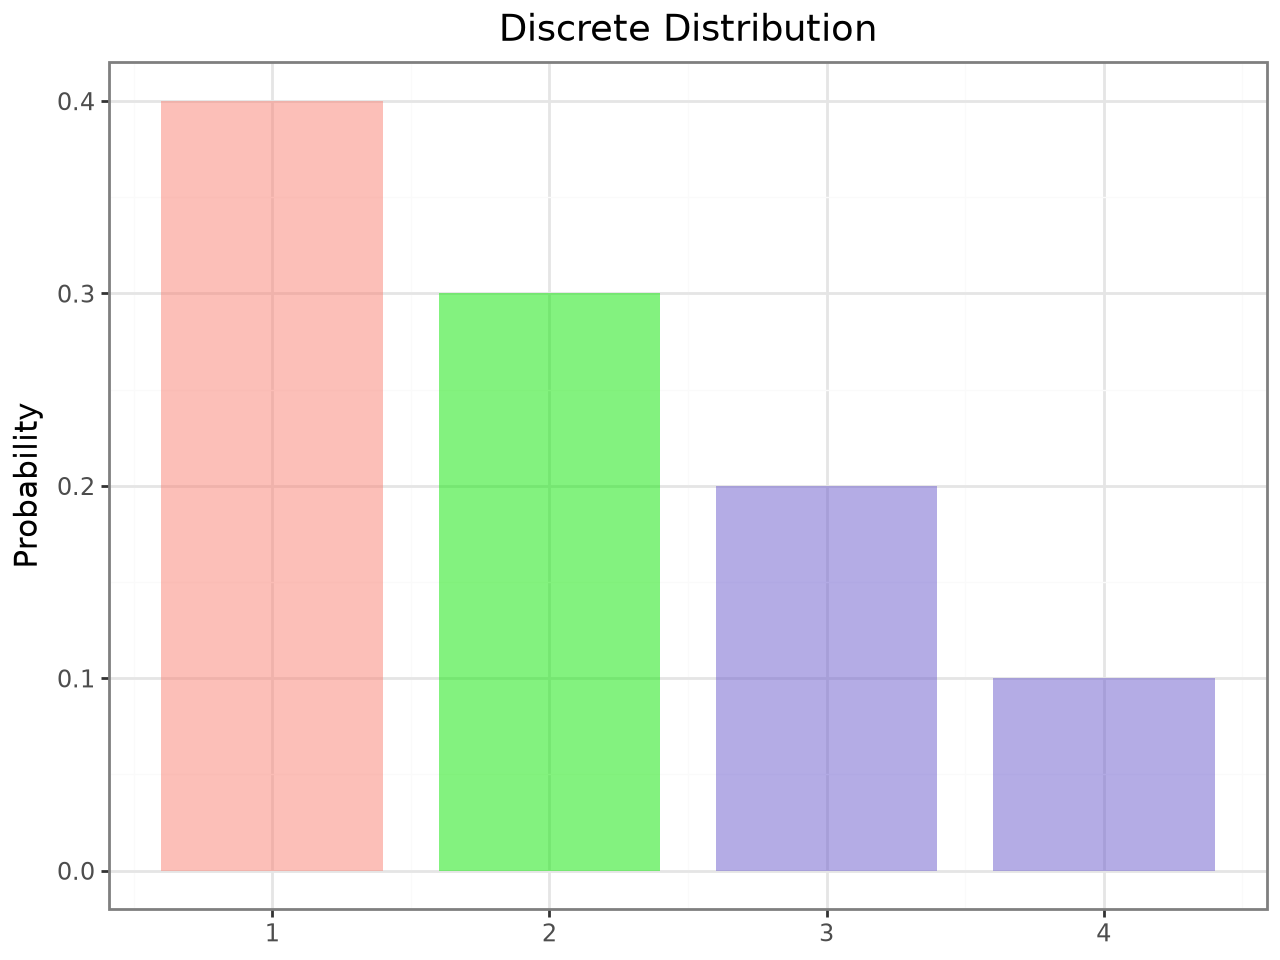

In [2]:
pc = rsm.basics.prob_calc("disc", v=[1, 2, 3, 4], p=[0.4, 0.3, 0.2, 0.1], lb=2)
pc.summary()
pc.plot()

(a) The mean number of cups a customer buys is **2**. The standard deviation is 1 and the variance is its square, so the variance is **1** as well.

(b) With the lower bound at 2, `P(X >= 2)` is the probability of buying 2 or more cups: **0.6**.

## Example 2: Brita water filters

Brita faucet water filters claim on their packaging to last 100 gallons. A red LED indicator on the filter signals when 100 gallons have been processed and the filter needs to be replaced. Historically the filters have signaled replacement at 100 gallons on average, with a standard deviation of 8 gallons. The number of gallons before the filter signals replacement is normally distributed with that mean and standard deviation. Working within Brita's center of expertise on quality assurance and control, your boss has asked you to investigate some concerns.

(a) What is the probability that a filter's signal occurs within ±10 gallons of the mean?<br>
(b) A filter whose signal occurs within ±10 gallons of the mean is within specification (good quality). If quality control examines 5 filters from the manufacturing line, what is the probability that at least 3 of them are within specification?

**Radiant, part (a).** Select `Normal`, set the `Mean` to 100 and the `St. dev` to 8. ±10 gallons from the mean is the range from 90 to 110, so choose `Values` and set the `Lower bound` to 90 and the `Upper bound` to 110.

![Example 2a in Radiant: normal distribution with mean 100 and standard deviation 8, bounds 90 and 110](figures/prob-calc-examples/ex2a-brita-normal.png)

Probability Calculator
Distribution: Normal
Mean        : 100
St. dev     : 8
Lower bound : 90
Upper bound : 110

P(X < 90) = 0.106
P(X > 90) = 0.894
P(X < 110) = 0.894
P(X > 110) = 0.106
P(90 < X < 110)     = 0.789
1 - P(90 < X < 110) = 0.211


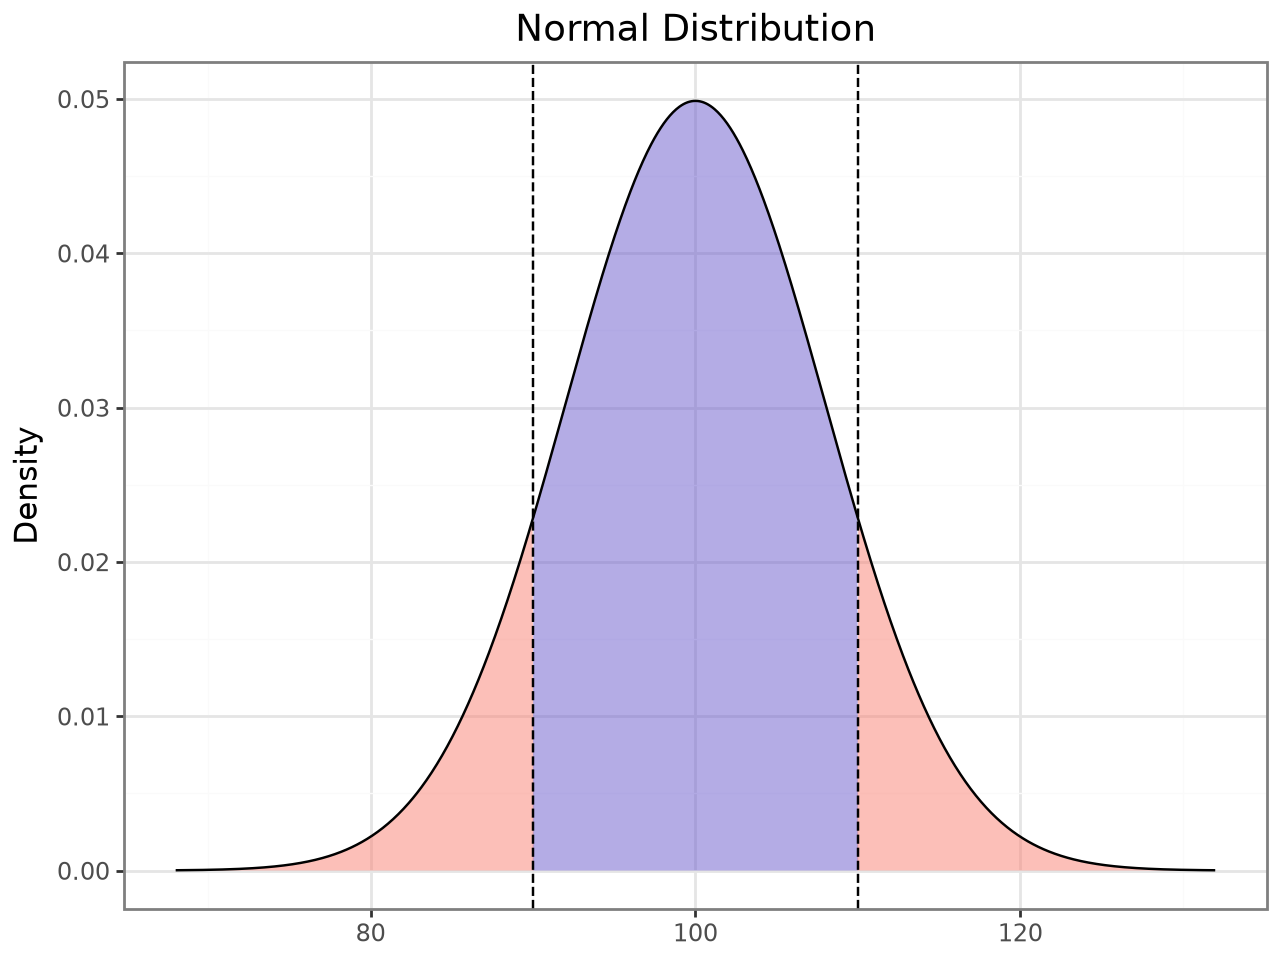

In [3]:
pc = rsm.basics.prob_calc("norm", mean=100, sd=8, lb=90, ub=110)
pc.summary()
pc.plot()

The probability that a filter signals within ±10 gallons of the mean, `P(90 < X < 110)`, is **0.789**.

**Radiant, part (b).** Each of the 5 filters is either within specification (probability 0.789, from part (a)) or not, independently of the others: a Binomial distribution with `n` = 5 and `p` = 0.789. "At least 3" is a lower bound of 3.

![Example 2b in Radiant: binomial distribution with n 5 and p 0.789, lower bound 3](figures/prob-calc-examples/ex2b-brita-binomial.png)

Probability Calculator
Distribution: Binomial
n           : 5
p           : 0.789
Mean        : 3.945
St. dev     : 0.912
Lower bound : 3
Upper bound : 

P(X  = 3) = 0.219
P(X  < 3) = 0.067
P(X <= 3) = 0.285
P(X  > 3) = 0.714
P(X >= 3) = 0.933


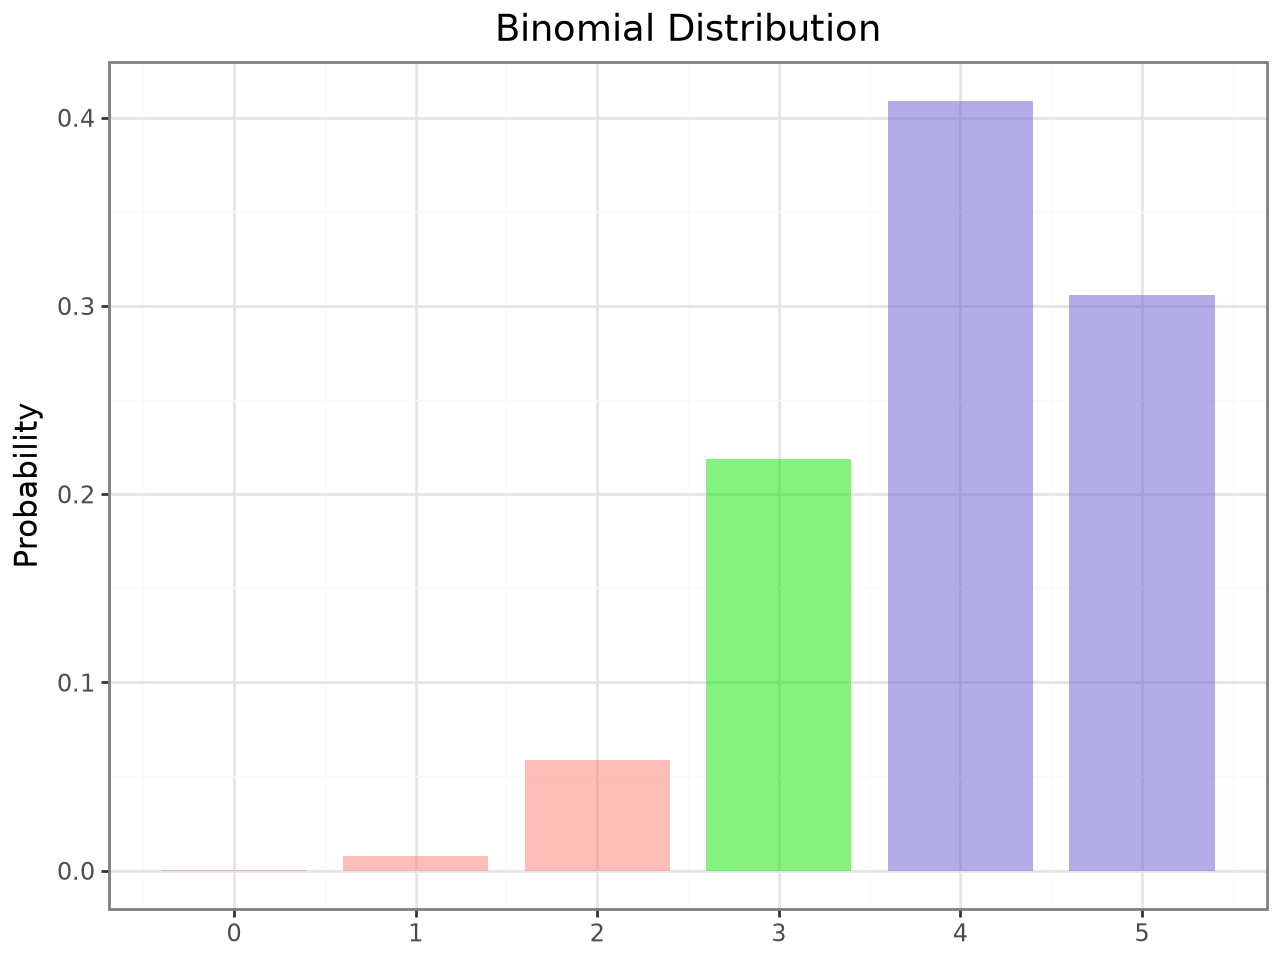

In [4]:
pc = rsm.basics.prob_calc("binom", n=5, p=0.789, lb=3)
pc.summary()
pc.plot()

The probability that at least 3 of the 5 filters are within specification, `P(X >= 3)`, is **0.933**.

## Example 3: gasoline sales at RadyClean

The amount of gasoline sold every day at the RadyClean gas station follows a uniform distribution between 1,500 and 4,000 gallons. RadyClean begins each day with a full tank of 4,000 gallons.

(a) What is the probability that RadyClean will sell at least 3,000 gallons in a day?<br>
(b) If we track the amount of gasoline sold for 7 days, what is the probability that on at least 3 of those days RadyClean sells at least 3,000 gallons?

**Radiant, part (a).** Select `Uniform` with `Min` 1500 and `Max` 4000, choose `Values` and set the `Lower bound` to 3000.

![Example 3a in Radiant: uniform distribution between 1500 and 4000, lower bound 3000](figures/prob-calc-examples/ex3a-gas-uniform.png)

Probability Calculator
Distribution: Uniform
Min         : 1500
Max         : 4000
Mean        : 2750
St. dev     : 721.688
Lower bound : 3000
Upper bound : 4000

P(X < 3000) = 0.6
P(X > 3000) = 0.4


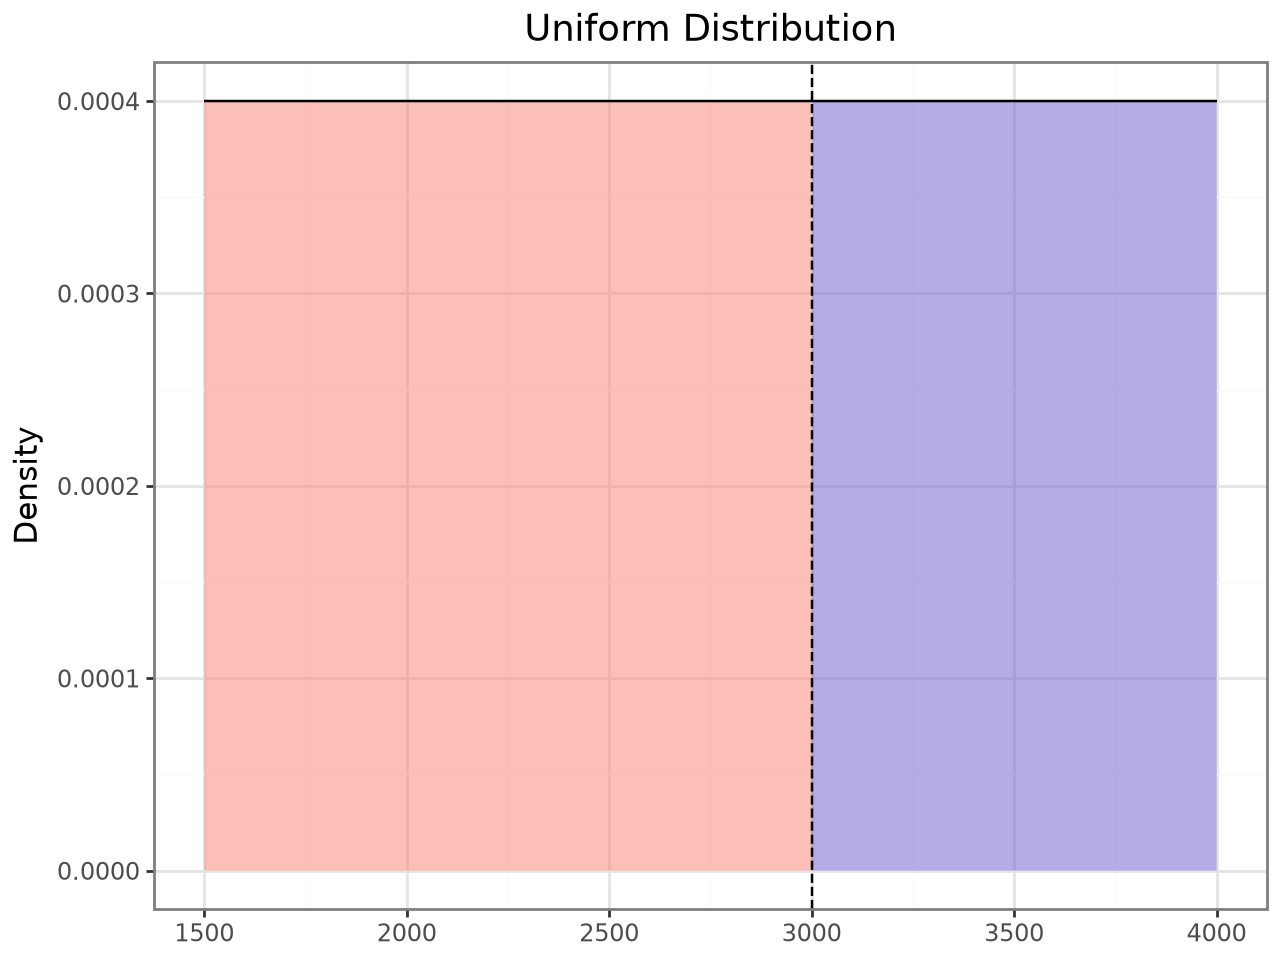

In [5]:
pc = rsm.basics.prob_calc("unif", min=1500, max=4000, lb=3000)
pc.summary()
pc.plot()

The probability of selling more than 3,000 gallons is **0.4**. Gallons sold is a continuous variable, so the probability of selling *exactly* 3,000 gallons is zero, and "at least 3,000" has the same probability as "more than 3,000": 0.4.

**Radiant, part (b).** Each day either sells at least 3,000 gallons (probability 0.4, from part (a)) or not. Over 7 independent days that is a Binomial distribution with `n` = 7 and `p` = 0.4; "at least 3 days" is a lower bound of 3.

![Example 3b in Radiant: binomial distribution with n 7 and p 0.4, lower bound 3](figures/prob-calc-examples/ex3b-gas-binomial.png)

Probability Calculator
Distribution: Binomial
n           : 7
p           : 0.4
Mean        : 2.8
St. dev     : 1.296
Lower bound : 3
Upper bound : 

P(X  = 3) = 0.29
P(X  < 3) = 0.42
P(X <= 3) = 0.71
P(X  > 3) = 0.29
P(X >= 3) = 0.58


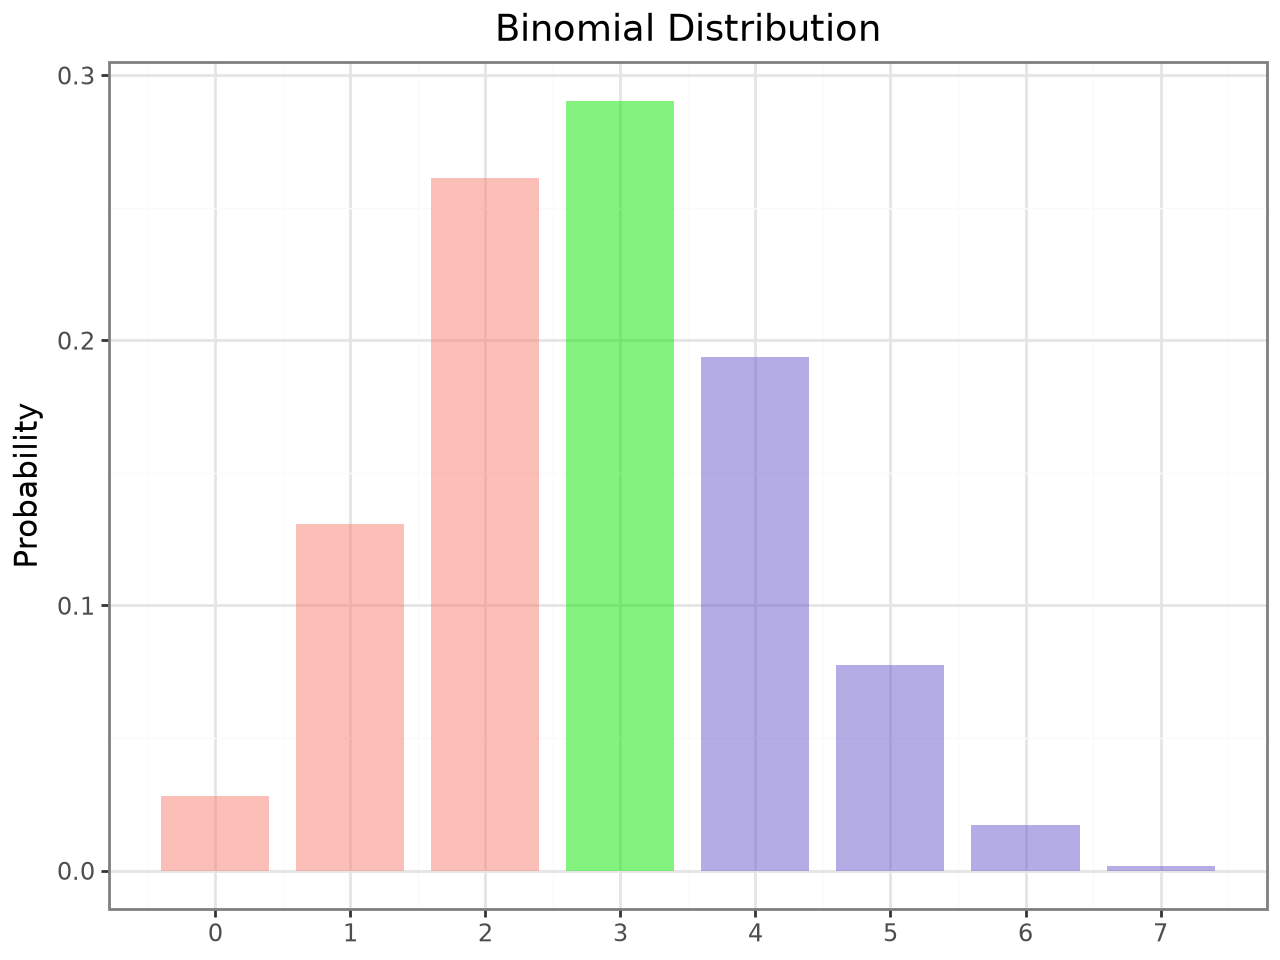

In [6]:
pc = rsm.basics.prob_calc("binom", n=7, p=0.4, lb=3)
pc.summary()
pc.plot()

The probability that at least 3 of the 7 days sell at least 3,000 gallons, `P(X >= 3)`, is **0.58**.

## Example 4: stocking newspapers

The owner of a convenience store in Fallbrook, CA sells both the LA Times and the San Diego Union Tribune. At the end of most days many copies are left on the shelf and have to be discarded. The owner's daughter, Carol, who is working on her MBA at a nearby university, wants to set a stocking policy that covers demand for each paper with 90% probability. From past weekday sales she estimates that LA Times sales are normally distributed with mean 90 and standard deviation 28, and San Diego Union Tribune (SDUT) sales are normally distributed with mean 150 and standard deviation 42.

How many copies of each paper should she stock on a weekday?

**Radiant, LA Times.** Select `Normal` with `Mean` 90 and `St. dev` 28. We know the probability (90%) and want the number of copies, so choose `Probabilities` as the `Calculation type`, set the `Upper bound (prob)` to 0.9 and clear the lower bound.

![Example 4 in Radiant: normal distribution with mean 90 and standard deviation 28, upper probability bound 0.9](figures/prob-calc-examples/ex4a-latimes.png)

Probability Calculator
Distribution: Normal
Mean        : 90
St. dev     : 28
Lower bound : 0
Upper bound : 0.9

P(X < 125.883) = 0.9
P(X > 125.883) = 0.1


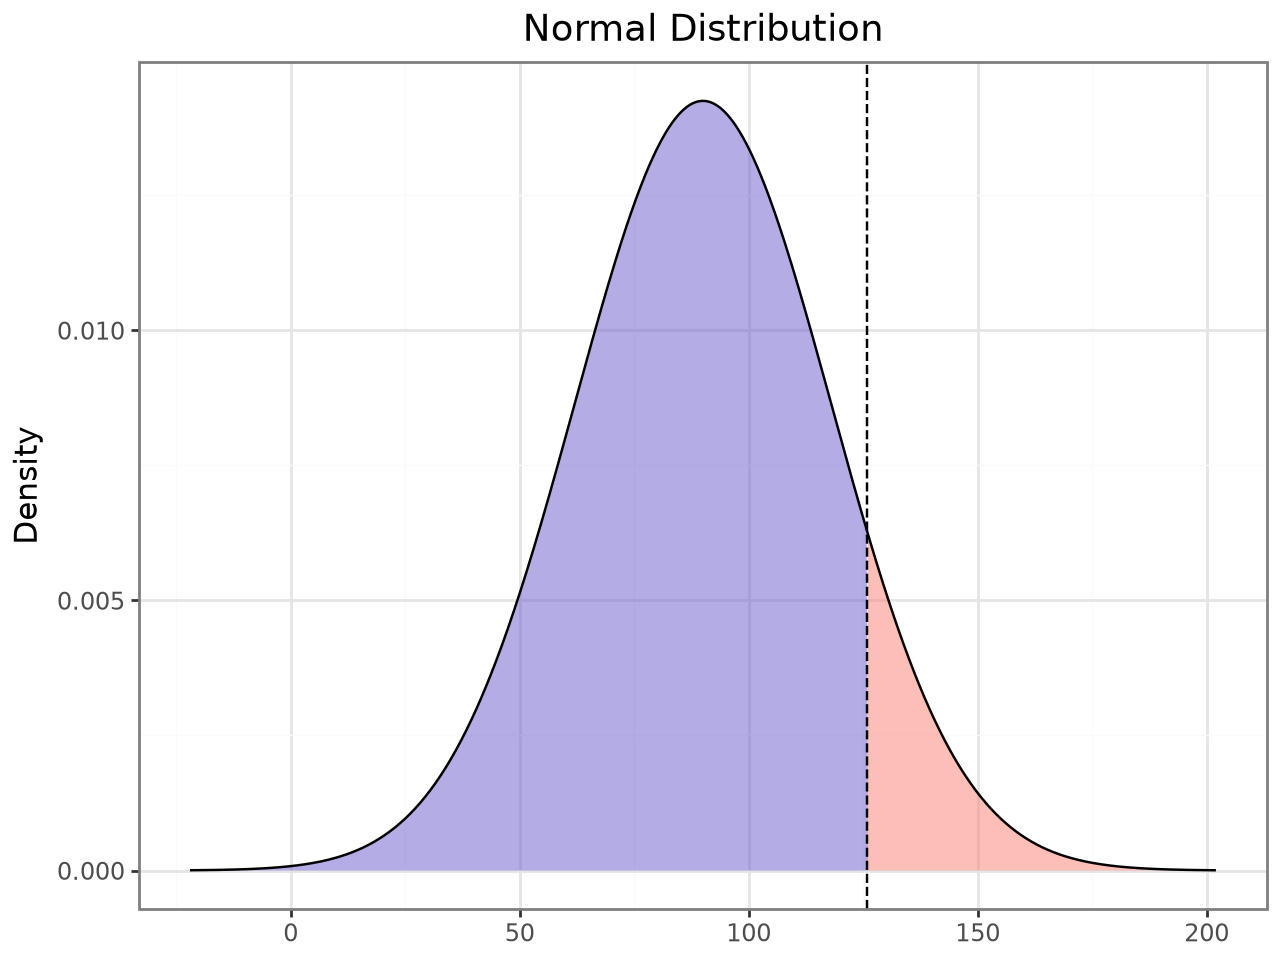

In [7]:
pc = rsm.basics.prob_calc("norm", mean=90, sd=28, pub=0.9)
pc.summary()
pc.plot()

The cutoff is 125.883 copies. Copies come in whole numbers, so round **up** to **126**: stocking 125 would cover demand with a probability just below 90%.

**Radiant, SDUT.** The same calculation with `Mean` 150 and `St. dev` 42.

![Example 4 in Radiant: normal distribution with mean 150 and standard deviation 42, upper probability bound 0.9](figures/prob-calc-examples/ex4b-sdut.png)

Probability Calculator
Distribution: Normal
Mean        : 150
St. dev     : 42
Lower bound : 0
Upper bound : 0.9

P(X < 203.825) = 0.9
P(X > 203.825) = 0.1


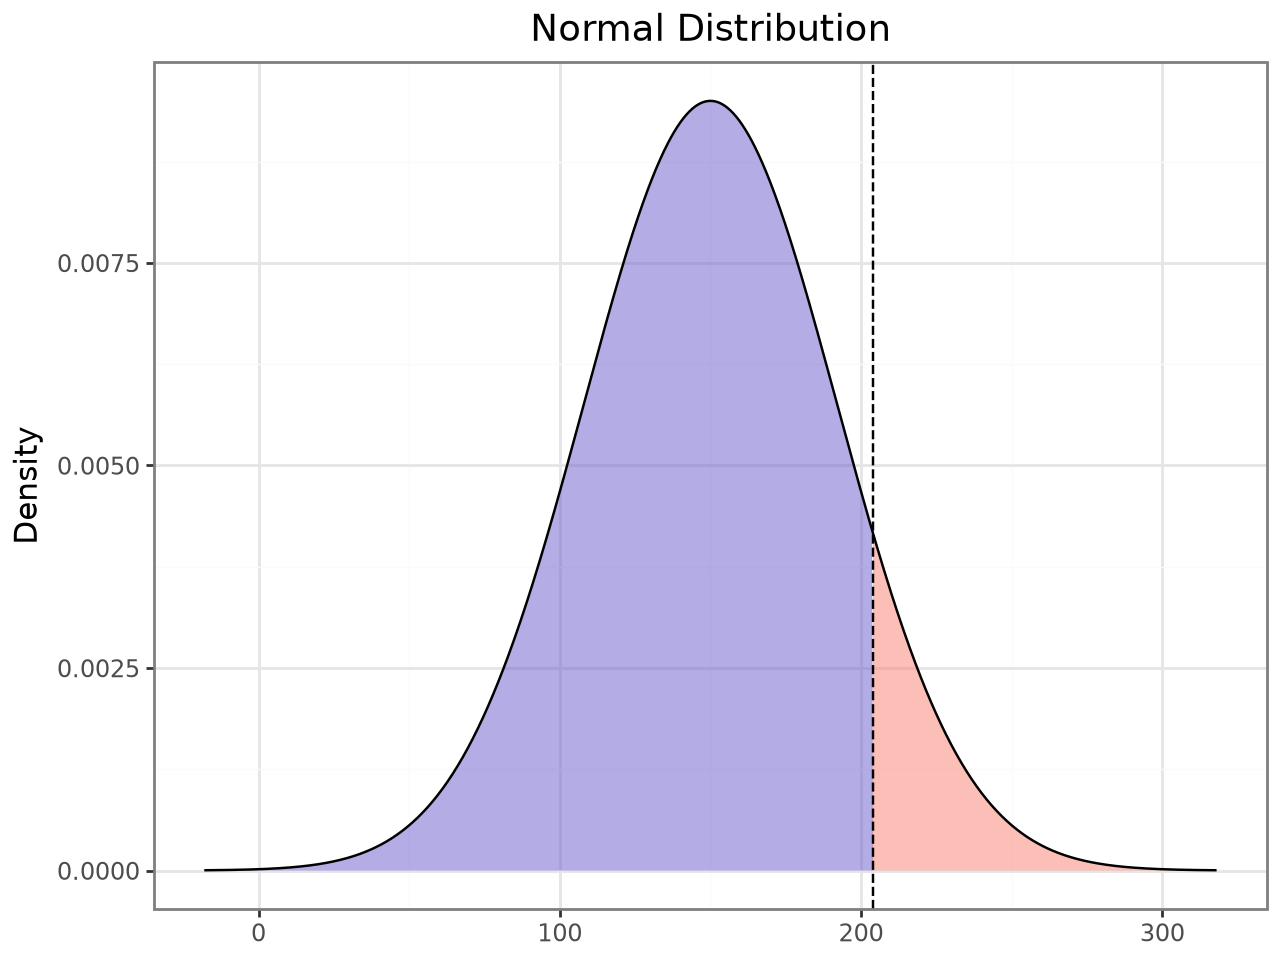

In [8]:
pc = rsm.basics.prob_calc("norm", mean=150, sd=42, pub=0.9)
pc.summary()
pc.plot()

The cutoff is 203.825, so the store should stock **204** copies of the San Diego Union Tribune.